# Visual odometry II: RGB-D odometry, keyframes, drift and failure cases

Notebook 01 built the two VO measurements (essential matrix and PnP) and chained them on the
easy fr1/xyz sequence. Here we turn them into complete pipelines, run them on **two** TUM
RGB-D sequences and study what makes odometry drift or fail:

| pipeline | measurement | scale | evaluated with |
|---|---|---|---|
| mono-E, oracle scale | essential matrix between keyframes | copied from ground truth (cheat) | SE(3) ATE |
| mono-E, unit scale | essential matrix between keyframes | 1 per keyframe step | Sim(3) ATE |
| mono map | PnP against points triangulated between keyframes | fixed by the first baseline | Sim(3) ATE |
| RGB-D frame-to-frame | PnP against the previous frame's depth points | metric | SE(3) ATE |
| RGB-D keyframes | PnP against the last keyframe's depth points | metric | SE(3) ATE |

The RGB-D pipelines run with ORB and with SIFT features.

**What you'll learn**
- how the motion profile of a sequence (speed, rotation rate) drives VO difficulty,
- why tracking against a **keyframe** instead of the previous frame changes the drift,
- how monocular **scale drift** shows up and why a Sim(3) alignment cannot hide it,
- how to diagnose **failure cases** (fast rotation, motion blur, few inliers) frame by frame,
- accuracy vs runtime of ORB and SIFT front ends on a CPU.

**Prerequisites:** notebook 01 of this project. Data: `make data-12_visual_odometry`.
Runtime: roughly 5 minutes on the CPU (14 full VO runs).

## Setup

Same imports and helpers as notebook 01; the pipelines are in
`projects/12_visual_odometry/scripts/vo.py`.

In [1]:
# --- Setup: imports, seeding, repository paths and plot style ---
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cvlab import device, io, tum, viz
from cvlab.geometry import invert_T, rotation_error_deg

PROJECT = "12_visual_odometry"
sys.path.insert(0, str(io.project_dir(PROJECT) / "scripts"))
import vo  # noqa: E402

dev = device.setup(seed=0)
viz.set_style()
ROOT = io.repo_root()
RUNS = io.runs_dir(PROJECT, create=True)
RESULTS = io.project_dir(PROJECT) / "results"
RESULTS.mkdir(exist_ok=True)
SEQ_DIRS = {
    "fr1_xyz": io.data_dir("tum", "fr1_xyz", "rgbd_dataset_freiburg1_xyz"),
    "fr1_desk": io.data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk"),
}
for name, path in SEQ_DIRS.items():
    print(f"{name}: {path.relative_to(ROOT)} | found: {path.exists()}")

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
fr1_xyz: data/tum/fr1_xyz/rgbd_dataset_freiburg1_xyz | found: True
fr1_desk: data/tum/fr1_desk/rgbd_dataset_freiburg1_desk | found: True


## 1. Two sequences, two difficulty levels

The camera motion between two frames decides how much the images overlap and how much they
blur. From the ground-truth poses we compute the **linear speed**
$v_k = \lVert p_{k+1} - p_k \rVert / \Delta t$ and the **angular speed**
$\omega_k = \angle(R_k^\top R_{k+1}) / \Delta t$, where
$\angle(R) = \arccos\big((\mathrm{tr}\,R - 1)/2\big)$ is the rotation angle. Curves are
smoothed with a 5-frame moving average for readability.

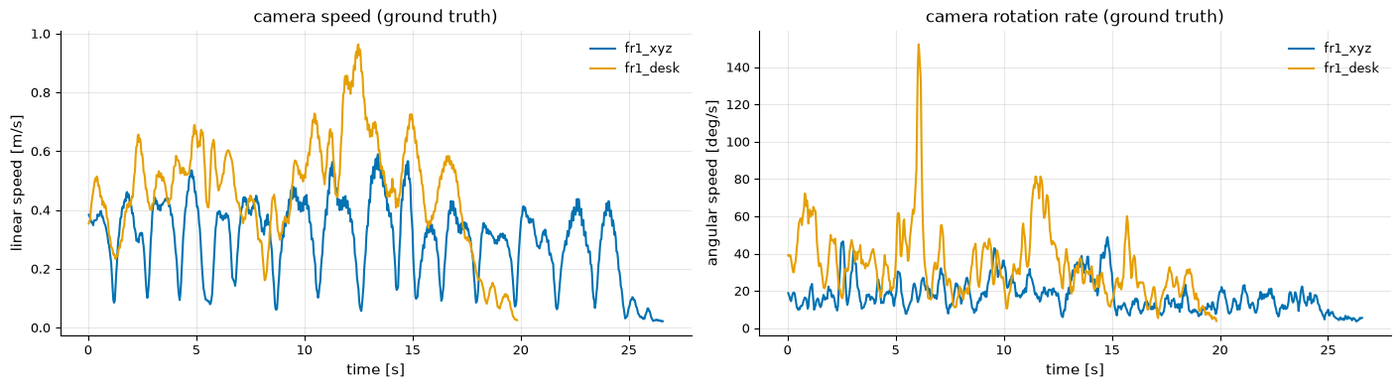

,sequence,frames,duration [s],path length [m],mean speed [m/s],max speed [m/s],mean rot. speed [deg/s],max rot. speed [deg/s]
0,fr1_xyz,790,26.57,8.01,0.30,0.59,17.29,48.82
1,fr1_desk,573,19.84,9.31,0.47,0.96,34.00,152.27


In [2]:
# --- Load both sequences and compare their motion profiles ---
seqs = {name: tum.load_sequence(path) for name, path in SEQ_DIRS.items()}


def motion_profile(seq):
    # finite differences of the GT poses at the associated RGB timestamps
    P, t = seq.gt_poses, seq.timestamps
    dt = np.diff(t)
    lin = np.linalg.norm(np.diff(P[:, :3, 3], axis=0), axis=1) / dt
    ang = (
        np.array([rotation_error_deg(P[k][:3, :3], P[k + 1][:3, :3]) for k in range(len(P) - 1)])
        / dt
    )
    return t[1:] - t[0], lin, ang


def smooth(x):
    return pd.Series(x).rolling(5, center=True, min_periods=1).mean().to_numpy()


fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
stats = []
for k, (name, seq) in enumerate(seqs.items()):
    tt, lin, ang = motion_profile(seq)
    axes[0].plot(tt, smooth(lin), color=viz.color(k, unit=True), label=name)
    axes[1].plot(tt, smooth(ang), color=viz.color(k, unit=True), label=name)
    stats.append({"sequence": name, "frames": len(seq), "duration [s]": tt[-1],
                  "path length [m]": np.sum(lin * np.diff(seq.timestamps)),
                  "mean speed [m/s]": lin.mean(), "max speed [m/s]": smooth(lin).max(),
                  "mean rot. speed [deg/s]": ang.mean(),
                  "max rot. speed [deg/s]": smooth(ang).max()})  # fmt: skip
axes[0].set_ylabel("linear speed [m/s]")
axes[1].set_ylabel("angular speed [deg/s]")
for ax, title in zip(axes, ["camera speed (ground truth)", "camera rotation rate (ground truth)"]):
    ax.set_xlabel("time [s]")
    ax.set_title(title)
    ax.legend()
viz.savefig(fig, PROJECT, "motion_profiles")
plt.show()
display(pd.DataFrame(stats).round(2))

fr1/desk moves faster and, above all, **rotates** faster than fr1/xyz (about twice as fast
on average, three times at the peak): a
rotation of $\omega$ deg/s shifts the image by about $f\,\omega\,\pi/180$ px/s
($f \approx 517$ px), so 100 deg/s is ~900 px/s, i.e. ~30 px between frames and a visible
smear during the exposure.

## 2. Running the pipelines

**Keyframes.** Frame-to-frame VO composes one noisy estimate per frame. A keyframe pipeline
keeps matching the current frame against the *same* reference keyframe and only switches
when tracking weakens (here: fewer than 150 PnP inliers). Between switches the error does not
accumulate; each switch adds one composition.

**Monocular map.** The *mono map* pipeline initialises from an essential matrix (baseline
length 1 defines the unit), triangulates the inlier matches and tracks later frames with PnP
against those points. A new keyframe is created when the inliers run low and there is enough
**translational parallax** - the image motion left after removing the rotation with the
infinite homography $H_\infty = K R K^{-1}$ (> 15 px), or when that parallax exceeds 40 px.
Pure rotation creates no baseline, so the raw pixel motion would be the wrong trigger.

At a keyframe all matches are triangulated with the PnP pose, and the *new* points are
rescaled to the points the keyframe already had: $s = \mathrm{median}(z_\text{map} /
z_\text{tri})$, the classic **relative-scale** trick. Without it, a PnP baseline whose
length is off by tens of percent (a small sideways shift looks much like a small rotation)
plants points of a different scale, and during development the map scale on fr1/xyz
collapsed within a few seconds. If PnP fails, the motion is re-estimated from an essential
matrix and scaled the same way; after 6 lost frames the map is re-initialised with its
median depth set to that of the lost map. All of this keeps the scale only *locally*:
errors in $s$ accumulate, and nothing (no bundle adjustment, no loop closure) pulls the
scale back - it **drifts**.

Every run below is deterministic (`cv2.setRNGSeed(0)` inside each pipeline); only the timings
change between executions.

In [3]:
# --- Run all pipelines on both sequences and save the trajectories (TUM format) ---
PIPELINES = {
    "mono-E, oracle scale": ("orb", "se3", lambda s, f: vo.run_mono_essential(s, f, scale="gt")),
    "mono-E, unit scale": ("orb", "sim3", lambda s, f: vo.run_mono_essential(s, f, scale="unit")),
    "mono map": ("orb", "sim3", lambda s, f: vo.run_pnp_vo(s, f, depth="triangulated")),
    "RGB-D frame-to-frame, ORB": ("orb", "se3", lambda s, f: vo.run_pnp_vo(s, f, keyframes=False)),
    "RGB-D keyframes, ORB": ("orb", "se3", lambda s, f: vo.run_pnp_vo(s, f, keyframes=True)),
    "RGB-D frame-to-frame, SIFT": (
        "sift",
        "se3",
        lambda s, f: vo.run_pnp_vo(s, f, keyframes=False),
    ),
    "RGB-D keyframes, SIFT": ("sift", "se3", lambda s, f: vo.run_pnp_vo(s, f, keyframes=True)),
}
fronts = {"orb": vo.FeatureFrontend("orb", 2000), "sift": vo.FeatureFrontend("sift", 2000)}
for f in fronts.values():
    f.detect(np.zeros((480, 640), np.uint8))  # warm-up
results, aligns = {}, {}
t_all = time.perf_counter()
for sname, seq in seqs.items():
    for method, (feat, align, run) in PIPELINES.items():
        t0 = time.perf_counter()
        res = run(seq, fronts[feat])
        results[sname, method], aligns[method] = res, align
        fname = f"{sname}_{method.replace(', ', '_').replace(' ', '-')}.txt"
        res.save_tum(RUNS / fname)
        print(f"{sname:8s} | {method:27s} | {len(res.frame_ids):3d} poses | "
              f"{res.ms_per_frame:5.1f} ms/frame | {time.perf_counter() - t0:5.1f} s")  # fmt: skip
print(f"total {time.perf_counter() - t_all:.0f} s; trajectories in {RUNS.relative_to(ROOT)}/")

fr1_xyz  | mono-E, oracle scale        | 178 poses |   8.1 ms/frame |  10.5 s


fr1_xyz  | mono-E, unit scale          | 178 poses |   7.6 ms/frame |   9.9 s


fr1_xyz  | mono map                    | 783 poses |   6.6 ms/frame |   8.9 s


fr1_xyz  | RGB-D frame-to-frame, ORB   | 790 poses |   9.8 ms/frame |  11.4 s


fr1_xyz  | RGB-D keyframes, ORB        | 790 poses |   6.8 ms/frame |   9.3 s


fr1_xyz  | RGB-D frame-to-frame, SIFT  | 790 poses |  24.2 ms/frame |  23.5 s


... (4 outputs left out)

fr1_desk | RGB-D frame-to-frame, ORB   | 573 poses |  10.1 ms/frame |   8.4 s


fr1_desk | RGB-D keyframes, ORB        | 573 poses |   7.0 ms/frame |   6.8 s


fr1_desk | RGB-D frame-to-frame, SIFT  | 573 poses |  23.3 ms/frame |  16.5 s


fr1_desk | RGB-D keyframes, SIFT       | 573 poses |  20.8 ms/frame |  15.2 s
total 163 s; trajectories in runs/12_visual_odometry/


## 3. Metrics for every run

As in notebook 01: Umeyama alignment (SE(3) for metric pipelines, Sim(3) for monocular ones),
**ATE** RMSE over all poses, **RPE** over 1 s (translation in cm, rotation in degrees), and
**drift** = RPE translation / distance travelled per second. *Coverage* is the fraction of
frames that received a pose (the monocular E-matrix pipelines only output keyframes). Every
ATE is re-computed with `evo` on the same pose pairs as a check.

In [4]:
# --- Evaluate all runs (cvlab metrics + evo cross-check) and save them as JSON / CSV ---
rows = []
for (sname, method), res in results.items():
    seq = seqs[sname]
    s = vo.evaluate(res, seq, align=aligns[method])
    ev = vo.evo_metrics(res.timestamps, res.poses, vo.gt_for(res, seq), align=aligns[method])
    assert np.isclose(ev["ate_rmse_m"], s["ate_rmse_m"], rtol=1e-6), (sname, method)
    rows.append({"sequence": sname, "method": method, "align": aligns[method].upper(),
                 "ATE [cm]": 100 * s["ate_rmse_m"], "ATE evo [cm]": 100 * ev["ate_rmse_m"],
                 "RPE 1s [cm]": 100 * s["rpe_trans_rmse_m"], "RPE 1s [deg]": s["rpe_rot_rmse_deg"],
                 "drift [%]": s["drift_pct"], "coverage [%]": 100 * s["poses"] / len(seq),
                 "keyframes": s["keyframes"], "lost": s["lost"],
                 "ms/frame": s["ms_per_frame"]})  # fmt: skip
df = pd.DataFrame(rows)
df.round(4).to_csv(RESULTS / "vo_metrics.csv", index=False)
io.save_json({"cpu": "Intel Core Ultra 9 275HX", "opencv": cv2.__version__,
              "rows": df.round(4).to_dict("records")}, RESULTS / "vo_metrics.json")  # fmt: skip
print("evo agrees with cvlab on every ATE; saved", (RESULTS / "vo_metrics.json").relative_to(ROOT))
display(df.drop(columns=["ATE evo [cm]"]).round(2))

evo agrees with cvlab on every ATE; saved projects/12_visual_odometry/results/vo_metrics.json


,sequence,method,align,ATE [cm],RPE 1s [cm],RPE 1s [deg],drift [%],coverage [%],keyframes,lost,ms/frame
0,fr1_xyz,"mono-E, oracle scale",SE3,6.41,4.45,2.53,14.75,22.53,177,1,8.08
1,fr1_xyz,"mono-E, unit scale",SIM3,6.52,7.60,2.53,25.22,22.53,177,1,7.61
2,fr1_xyz,mono map,SIM3,7.72,8.49,3.92,28.18,99.11,72,0,6.58
3,fr1_xyz,"RGB-D frame-to-frame, ORB",SE3,4.82,3.20,1.67,10.61,100.00,790,0,9.78
4,fr1_xyz,"RGB-D keyframes, ORB",SE3,3.79,2.23,1.32,7.41,100.00,39,0,6.81
5,fr1_xyz,"RGB-D frame-to-frame, SIFT",SE3,5.09,2.09,1.15,6.93,100.00,790,0,24.19
6,fr1_xyz,"RGB-D keyframes, SIFT",SE3,5.17,2.17,1.26,7.21,100.00,118,0,21.06
7,fr1_desk,"mono-E, oracle scale",SE3,19.14,11.96,5.44,25.48,27.57,157,1,7.46
8,fr1_desk,"mono-E, unit scale",SIM3,39.79,24.83,5.44,52.91,27.57,157,1,7.42
9,fr1_desk,mono map,SIM3,69.91,37.79,20.75,80.51,99.13,91,3,7.74


## 4. Keyframes vs frame-to-frame

The plot shows the aligned position error over time for the four RGB-D runs; tick marks at
the bottom are the keyframe switches of the ORB keyframe run.

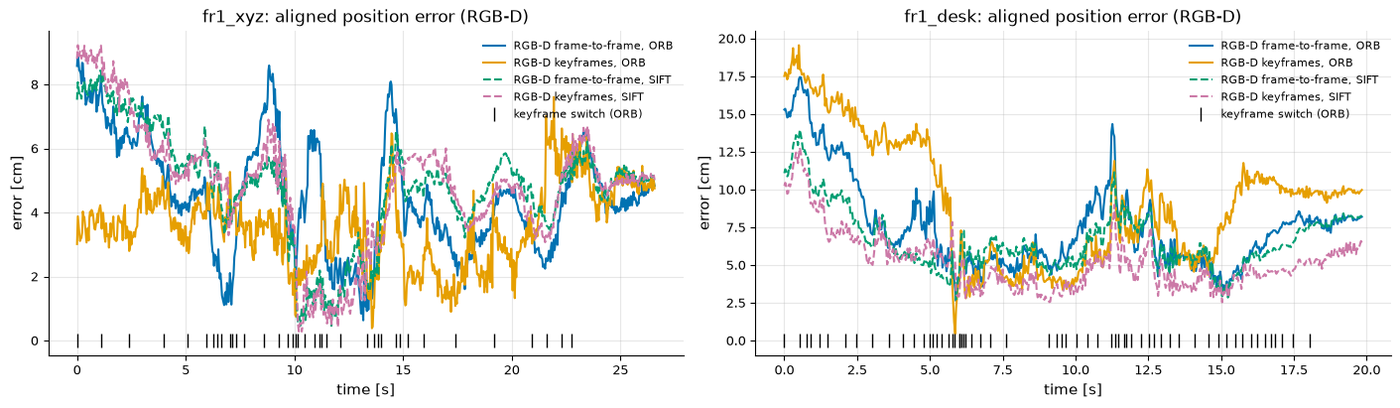

ATE [cm]         RPE 1s [cm]         keyframes  \
sequence                   fr1_desk fr1_xyz    fr1_desk fr1_xyz  fr1_desk   
method                                                                      
RGB-D frame-to-frame, ORB      8.18    4.82        4.05    3.20     573.0   
RGB-D frame-to-frame, SIFT     7.01    5.09        3.27    2.09     573.0   
RGB-D keyframes, ORB          10.11    3.79        4.22    2.23      62.0   
RGB-D keyframes, SIFT          5.59    5.17        2.89    2.17     185.0   

                                    
sequence                   fr1_xyz  
method                              
RGB-D frame-to-frame, ORB    790.0  
RGB-D frame-to-frame, SIFT   790.0  
RGB-D keyframes, ORB          39.0  
RGB-D keyframes, SIFT        118.0

In [5]:
# --- Position error over time: frame-to-frame vs keyframe tracking (RGB-D) ---
def aligned_error(sname, method):
    res, seq = results[sname, method], seqs[sname]
    gt = vo.gt_for(res, seq)
    P, _ = vo.align_poses(res.poses, gt, aligns[method])
    return res.timestamps - seq.timestamps[0], np.linalg.norm(P[:, :3, 3] - gt[:, :3, 3], axis=1)


rgbd = [m for m in PIPELINES if m.startswith("RGB-D")]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.0))
for ax, sname in zip(axes, seqs):
    for k, method in enumerate(rgbd):
        tt, err = aligned_error(sname, method)
        ax.plot(tt, 100 * err, color=viz.color(k, unit=True), ls="-" if "ORB" in method else "--",
                label=method)  # fmt: skip
    res = results[sname, "RGB-D keyframes, ORB"]
    kf_t = (
        seqs[sname].timestamps[res.log["frame"][res.log["status"] == "kf"]]
        - seqs[sname].timestamps[0]
    )
    ax.plot(kf_t, np.zeros_like(kf_t), "|", color="k", ms=10, label="keyframe switch (ORB)")
    ax.set_title(f"{sname}: aligned position error (RGB-D)")
    ax.set_xlabel("time [s]")
    ax.set_ylabel("error [cm]")
    ax.legend(fontsize=8)
viz.savefig(fig, PROJECT, "keyframes_vs_f2f")
plt.show()
display(df[df.method.str.startswith("RGB-D")].pivot(index="method", columns="sequence",
                                                    values=["ATE [cm]", "RPE 1s [cm]", "keyframes"]).round(2))  # fmt: skip

## 5. Monocular scale drift

After a Sim(3) alignment the *global* scale is right on average, but the *local* scale can
still wander. We measure it over 1-s windows:
$$\text{local scale}(i) = \frac{\lVert p_{j} - p_{i} \rVert}{\lVert g_{j} - g_{i} \rVert},
\qquad t_j \approx t_i + 1\,\text{s},$$
using the aligned estimate $p$ and ground truth $g$ (windows where the camera moved less than
5 cm are skipped, the ratio is meaningless there). A perfect metric trajectory gives 1
everywhere. For the oracle-scale pipeline it is 1 by construction up to direction errors, so it
is not shown.

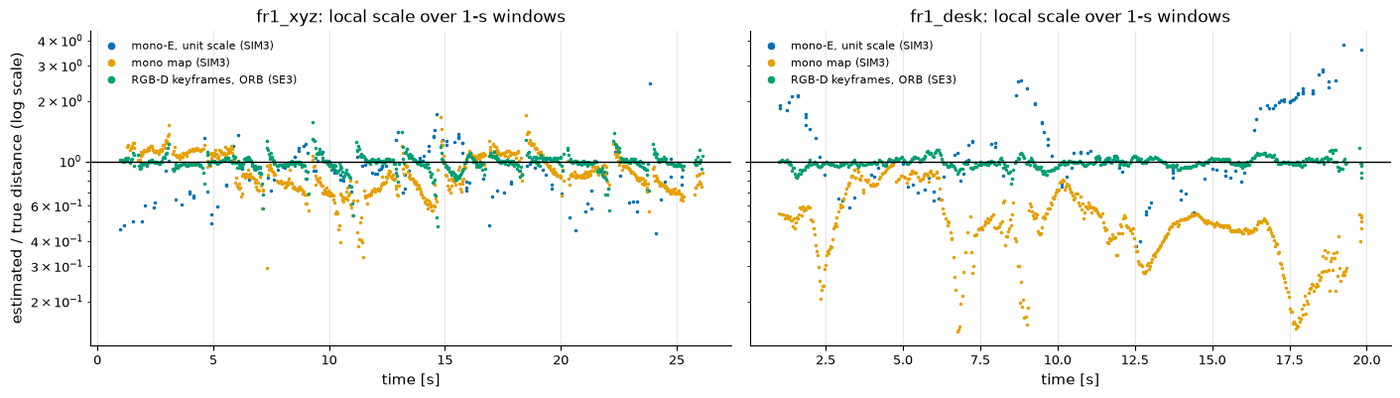

,sequence,method,windows,median local scale,10th pct,90th pct
0,fr1_xyz,"mono-E, unit scale",142,0.89,0.60,1.24
1,fr1_xyz,mono map,679,0.86,0.68,1.14
2,fr1_xyz,"RGB-D keyframes, ORB",686,0.99,0.89,1.07
3,fr1_desk,"mono-E, unit scale",137,1.07,0.68,2.21
4,fr1_desk,mono map,529,0.49,0.25,0.82
5,fr1_desk,"RGB-D keyframes, ORB",534,0.99,0.93,1.05


In [6]:
# --- Local scale factor over time for the monocular pipelines (after Sim(3) alignment) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 3.9), sharey=True)
scale_stats = []
for ax, sname in zip(axes, seqs):
    seq = seqs[sname]
    for k, method in enumerate(["mono-E, unit scale", "mono map", "RGB-D keyframes, ORB"]):
        res = results[sname, method]
        gt = vo.gt_for(res, seq)
        P, _ = vo.align_poses(res.poses, gt, aligns[method])
        rp = vo.rpe_time(res.timestamps, P, gt, delta_s=1.0)
        i, j = rp["i"], rp["j"]
        d_gt = np.linalg.norm(gt[j, :3, 3] - gt[i, :3, 3], axis=1)
        keep = d_gt > 0.05
        ratio = np.linalg.norm(P[j, :3, 3] - P[i, :3, 3], axis=1)[keep] / d_gt[keep]
        ax.plot(rp["t"][keep] - seq.timestamps[0], ratio, ".", ms=3, color=viz.color(k, unit=True),
                label=f"{method} ({aligns[method].upper()})")  # fmt: skip
        q10, q90 = np.percentile(ratio, [10, 90])
        scale_stats.append({"sequence": sname, "method": method, "windows": int(keep.sum()),
                            "median local scale": np.median(ratio), "10th pct": q10,
                            "90th pct": q90})  # fmt: skip
    ax.axhline(1.0, color="k", lw=1)
    ax.set_yscale("log")
    ax.set_title(f"{sname}: local scale over 1-s windows")
    ax.set_xlabel("time [s]")
    ax.legend(fontsize=8, markerscale=3)
axes[0].set_ylabel("estimated / true distance (log scale)")
viz.savefig(fig, PROJECT, "mono_scale_drift")
plt.show()
display(pd.DataFrame(scale_stats).round(2))

## 6. Failure cases on fr1/desk: fast rotation and motion blur

To find out *when* the RGB-D tracker struggles we look at single frames of the ORB
frame-to-frame run on fr1/desk:

* **per-frame error** = translation part of the RPE between consecutive frames,
* **angular speed** from the ground truth,
* **blur score** = variance of the Laplacian of the grey image (low = blurry; it also drops for
  texture-poor views, so it is only a rough proxy),
* **PnP inliers** from the tracker log.

Spearman rank correlations quantify which factor goes together with large errors.

In [7]:
# --- Per-frame diagnostics of the ORB frame-to-frame run on fr1/desk ---
sname, method = "fr1_desk", "RGB-D frame-to-frame, ORB"
seq, res = seqs[sname], results[sname, method]
gt, est = vo.gt_for(res, seq), res.poses
dt = np.diff(res.timestamps)
E = [
    invert_T(invert_T(gt[k]) @ gt[k + 1]) @ (invert_T(est[k]) @ est[k + 1])
    for k in range(len(est) - 1)
]
frame_err_mm = 1000 * np.array([np.linalg.norm(e[:3, 3]) for e in E])
ang = (
    np.array([rotation_error_deg(gt[k][:3, :3], gt[k + 1][:3, :3]) for k in range(len(gt) - 1)])
    / dt
)
blur = np.array([cv2.Laplacian(cv2.imread(str(seq.rgb_paths[i]), cv2.IMREAD_GRAYSCALE), cv2.CV_64F).var()
                 for i in res.frame_ids])  # fmt: skip
log_inl = dict(zip(res.log["frame"], res.log["n_inliers"]))
inliers = np.array([log_inl[i] for i in res.frame_ids])
diag = pd.DataFrame({"frame": res.frame_ids[1:], "t [s]": res.timestamps[1:] - seq.timestamps[0],
                     "error [mm]": frame_err_mm, "angular speed [deg/s]": ang,
                     "blur score": blur[1:], "PnP inliers": inliers[1:]})  # fmt: skip
corr = diag[["error [mm]", "angular speed [deg/s]", "blur score", "PnP inliers"]].corr("spearman")
print("Spearman correlation with the per-frame error:")
display(corr[["error [mm]"]].T.round(2))
worst = diag.nlargest(3, "error [mm]")
display(worst.round(1))
print(f"median per-frame error {np.median(frame_err_mm):.1f} mm; median motion per frame "
      f"{1000 * np.median(np.linalg.norm(np.diff(gt[:, :3, 3], axis=0), axis=1)):.1f} mm")  # fmt: skip

Spearman correlation with the per-frame error:


,error [mm],angular speed [deg/s],blur score,PnP inliers
error [mm],1.0,0.34,-0.01,-0.44


,frame,t [s],error [mm],angular speed [deg/s],blur score,PnP inliers
313,314,11.2,35.0,50.1,119.5,284
133,134,4.9,33.8,15.7,193.3,281
328,329,11.7,33.8,99.5,140.7,205


median per-frame error 5.7 mm; median motion per frame 16.1 mm


The figure stacks the three signals over time (red lines = the three worst frames) and shows
those frames: fast rotation smears the image and leaves fewer, less precise matches.

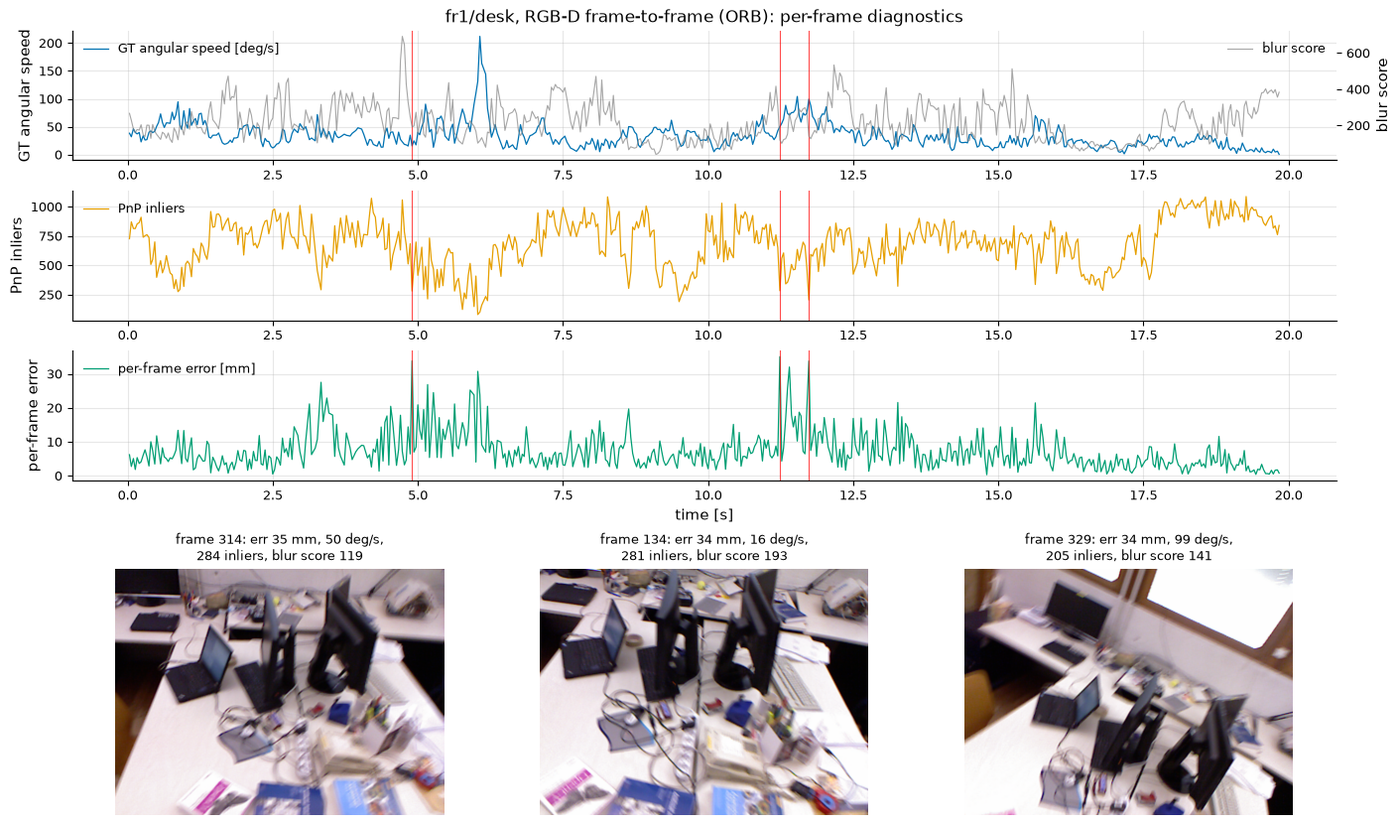

In [8]:
# --- Plot the diagnostics over time and show the three worst frames ---
fig = plt.figure(figsize=(14, 8.2))
gs = fig.add_gridspec(4, 3, height_ratios=[1, 1, 1, 1.9])
panels = [("angular speed [deg/s]", "GT angular speed [deg/s]"),
          ("PnP inliers", "PnP inliers"), ("error [mm]", "per-frame error [mm]")]  # fmt: skip
for r, (col, label) in enumerate(panels):
    ax = fig.add_subplot(gs[r, :])
    ax.plot(diag["t [s]"], diag[col], lw=0.9, color=viz.color(r, unit=True), label=label)
    if col == "angular speed [deg/s]":
        ax2 = ax.twinx()
        ax2.plot(
            diag["t [s]"], diag["blur score"], lw=0.8, color="gray", alpha=0.7, label="blur score"
        )
        ax2.set_ylabel("blur score")
        ax2.grid(False)
        ax2.legend(loc="upper right")
    for tw in worst["t [s]"]:
        ax.axvline(tw, color="red", lw=0.8, alpha=0.7)
    ax.set_ylabel(label.split(" [")[0])
    ax.legend(loc="upper left")
    if r == 0:
        ax.set_title("fr1/desk, RGB-D frame-to-frame (ORB): per-frame diagnostics")
    if r == 2:
        ax.set_xlabel("time [s]")
for c, (_, w) in enumerate(worst.iterrows()):
    ax = fig.add_subplot(gs[3, c])
    ax.imshow(seq.rgb(int(w["frame"])))
    ax.set_title(f"frame {int(w['frame'])}: err {w['error [mm]']:.0f} mm, "
                 f"{w['angular speed [deg/s]']:.0f} deg/s,\n{int(w['PnP inliers'])} inliers, "
                 f"blur score {w['blur score']:.0f}", fontsize=9)  # fmt: skip
    ax.axis("off")
viz.savefig(fig, PROJECT, "failure_cases")
plt.show()

## 7. Runtime

Mean processing time per frame on the CPU (Intel Core Ultra 9 275HX, OpenCV with all cores):
feature detection, matching, undistortion, depth lookup (RGB-D pipelines read the depth PNG of
every new reference frame inside the timed loop) and pose estimation. Reading the RGB PNG is
excluded. The feature table in notebook 01 shows that the detector dominates, and SIFT
detection is several times slower than ORB.

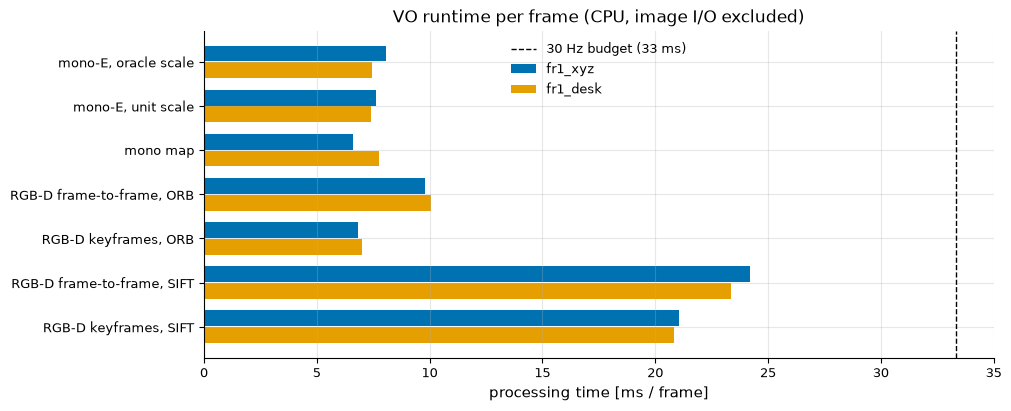

In [9]:
# --- Bar chart of ms/frame per pipeline and sequence ---
piv = df.pivot(index="method", columns="sequence", values="ms/frame").loc[list(PIPELINES)]
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(piv))
for k, sname in enumerate(seqs):
    ax.barh(y + 0.38 * k, piv[sname], height=0.36, color=viz.color(k, unit=True), label=sname)
ax.set_yticks(y + 0.19, piv.index)
ax.invert_yaxis()
ax.set_xlabel("processing time [ms / frame]")
ax.set_title("VO runtime per frame (CPU, image I/O excluded)")
ax.axvline(1000 / 30, color="k", ls="--", lw=1, label="30 Hz budget (33 ms)")
ax.legend()
viz.savefig(fig, PROJECT, "runtime")
plt.show()

## Results

**Trajectories.** Aligned estimates of five pipelines against the ground truth for both
sequences: top view (mocap x-y plane, z up) and every coordinate over time.

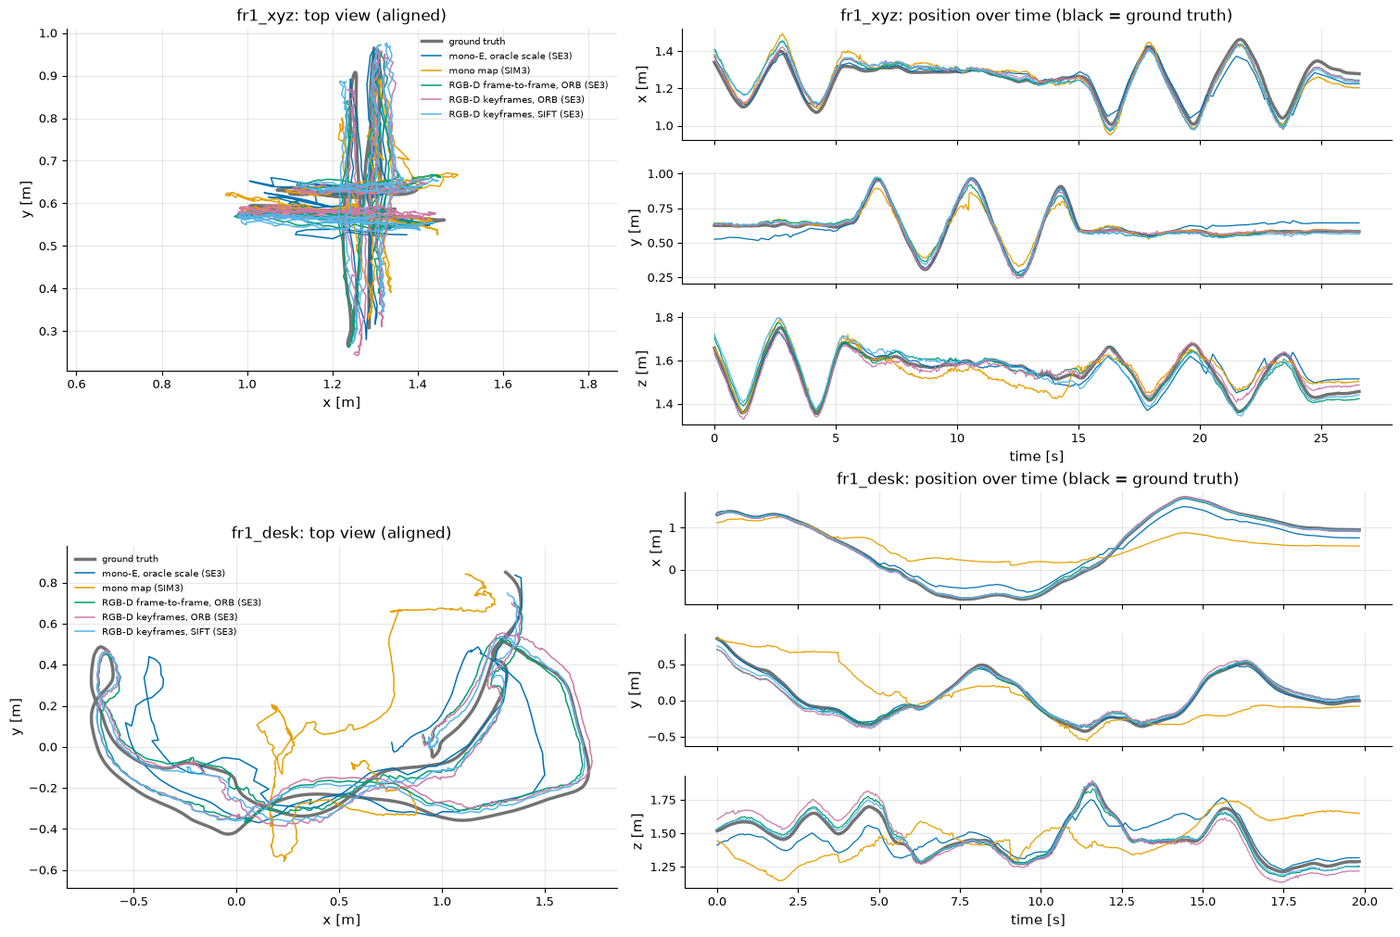

In [10]:
# --- Trajectory figure: top view + x/y/z over time for both sequences ---
show = ["mono-E, oracle scale", "mono map", "RGB-D frame-to-frame, ORB", "RGB-D keyframes, ORB",
        "RGB-D keyframes, SIFT"]  # fmt: skip
fig = plt.figure(figsize=(15, 10))
outer = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.4], hspace=0.25)
for r, (sname, seq) in enumerate(seqs.items()):
    g = seq.gt_poses[:, :3, 3]
    t0 = seq.timestamps[0]
    ax = fig.add_subplot(outer[r, 0])
    ax.plot(g[:, 0], g[:, 1], "k-", lw=2.5, alpha=0.55, label="ground truth")
    inner = outer[r, 1].subgridspec(3, 1, hspace=0.08)
    axd = [fig.add_subplot(inner[d]) for d in range(3)]
    for d in range(3):
        axd[d].plot(seq.timestamps - t0, g[:, d], "k-", lw=2.5, alpha=0.55)
    for k, method in enumerate(show):
        res = results[sname, method]
        P, _ = vo.align_poses(res.poses, vo.gt_for(res, seq), aligns[method])
        ax.plot(P[:, 0, 3], P[:, 1, 3], lw=1.1, color=viz.color(k, unit=True),
                label=f"{method} ({aligns[method].upper()})")  # fmt: skip
        for d in range(3):
            axd[d].plot(res.timestamps - t0, P[:, d, 3], lw=0.9, color=viz.color(k, unit=True))
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_title(f"{sname}: top view (aligned)")
    ax.legend(fontsize=7.5, loc="best")
    for d, lab in enumerate("xyz"):
        axd[d].set_ylabel(f"{lab} [m]")
        if d < 2:
            axd[d].tick_params(labelbottom=False)
    axd[0].set_title(f"{sname}: position over time (black = ground truth)")
    axd[2].set_xlabel("time [s]")
viz.savefig(fig, PROJECT, "trajectories")
plt.show()

**Summary table** of the measured numbers (also in
`projects/12_visual_odometry/results/vo_metrics.json` / `.csv`).

In [11]:
# --- Summary table: one row per pipeline, metrics per sequence ---
summary = df.pivot(index="method", columns="sequence",
                   values=["ATE [cm]", "RPE 1s [cm]", "RPE 1s [deg]", "coverage [%]", "ms/frame"])  # fmt: skip
summary = summary.loc[list(PIPELINES)]
display(summary.round(2))

ATE [cm]         RPE 1s [cm]         RPE 1s [deg]  \
sequence                   fr1_desk fr1_xyz    fr1_desk fr1_xyz     fr1_desk   
method                                                                         
mono-E, oracle scale          19.14    6.41       11.96    4.45         5.44   
mono-E, unit scale            39.79    6.52       24.83    7.60         5.44   
mono map                      69.91    7.72       37.79    8.49        20.75   
RGB-D frame-to-frame, ORB      8.18    4.82        4.05    3.20         2.56   
RGB-D keyframes, ORB          10.11    3.79        4.22    2.23         2.26   
RGB-D frame-to-frame, SIFT     7.01    5.09        3.27    2.09         2.01   
RGB-D keyframes, SIFT          5.59    5.17        2.89    2.17         1.82   

                                   coverage [%]         ms/frame          
sequence                   fr1_xyz     fr1_desk fr1_xyz fr1_desk fr1_xyz  
method                                                                    
mono-E, oracle scale          2.53        27.57   22.53     7.46    8.08  
mono-E, unit scale            2.53        27.57   22.53     7.42    7.61  
mono map                      3.92        99.13   99.11     7.74    6.58  
RGB-D frame-to-frame, ORB     1.67       100.00  100.00    10.05    9.78  
RGB-D keyframes, ORB          1.32       100.00  100.00     6.99    6.81  
RGB-D frame-to-frame, SIFT    1.15       100.00  100.00    23.34   24.19  
RGB-D keyframes, SIFT         1.26       100.00  100.00    20.82   21.06

A small thumbnail for the repository's project table: the fr1/desk trajectory of the RGB-D
keyframe tracker coloured by its position error.

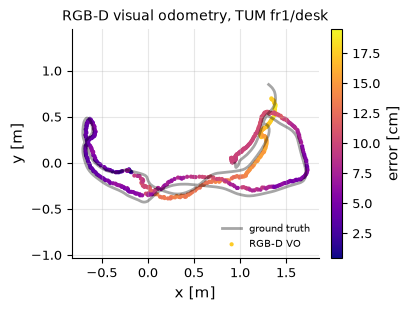

In [12]:
# --- README thumbnail (~400 px wide) ---
sname, method = "fr1_desk", "RGB-D keyframes, ORB"
res, seq = results[sname, method], seqs[sname]
gt = vo.gt_for(res, seq)
P, _ = vo.align_poses(res.poses, gt, "se3")
err = 100 * np.linalg.norm(P[:, :3, 3] - gt[:, :3, 3], axis=1)
fig, ax = plt.subplots(figsize=(4.0, 3.0))
ax.plot(gt[:, 0, 3], gt[:, 1, 3], "k-", lw=2, alpha=0.35, label="ground truth")
sc = ax.scatter(P[:, 0, 3], P[:, 1, 3], c=err, s=4, cmap="plasma", label="RGB-D VO")
fig.colorbar(sc, ax=ax, label="error [cm]")
ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("RGB-D visual odometry, TUM fr1/desk", fontsize=10)
ax.legend(fontsize=7, loc="lower right")
viz.savefig(fig, PROJECT, "thumb", dpi=100)
plt.show()

### Takeaways

* **The motion profile predicts the difficulty.** fr1/desk rotates twice as fast as fr1/xyz on
  average (34.00 vs 17.29 deg/s, smoothed peak 152.27 vs 48.82 deg/s) and every pipeline is
  worse on it.
* **RGB-D PnP is the robust choice.** All four RGB-D runs track every frame of both sequences,
  with an ATE of 3.79-5.17 cm on fr1/xyz and 5.59-10.11 cm on fr1/desk, and a drift of
  6-11 % of the distance travelled per second. Depth fixes the scale, so this is real odometry
  for a robot.
* **Keyframes are not a free win.** Matching against a keyframe cut the number of pose
  compositions from 790 to 39 on fr1/xyz and gave the best ORB result there (3.79 vs 4.82 cm
  ATE). On fr1/desk the ORB keyframe tracker was *worse* than frame-to-frame (10.11 vs
  8.18 cm), while SIFT gained (5.59 vs 7.01 cm). Every frame inherits the error of its keyframe,
  so one poorly estimated keyframe in a fast sweep biases everything tracked against it.
  Exercise 2 shows how sensitive the result is to the keyframe threshold.
* **SIFT gives the lowest drift** (RPE per second 2.09-3.27 cm vs 2.23-4.22 cm for ORB), at
  2.3-3.1 times the runtime of the matching ORB pipeline in this execution.
* **Monocular VO has no scale, and its luck runs out.** On fr1/xyz, unit-length keyframe steps
  plus one Sim(3) scale were almost as good as the oracle (6.52 vs 6.41 cm). On fr1/desk the
  ATE doubles (39.79 vs 19.14 cm): the true step length varies there, and the local scale
  ranges from 0.68 to 2.21 (10th-90th percentile). Even the oracle-scale run reaches 19.14 cm,
  because rotation and direction errors still accumulate (RPE 5.44 deg per second).
* **The monocular map shows scale drift and its limits.** On fr1/xyz it tracks 99 % of the
  frames with 7.72 cm Sim(3) ATE and a local scale between 0.68 and 1.14. On fr1/desk it fails:
  the local scale wanders between 0.25 and 0.82 (10th-90th percentile; the median of 0.49 also
  shows that a least-squares Sim(3) fit shrinks a trajectory whose shape is wrong), and the
  rotation drifts by 20.75 deg per second. The triangulated map is thin (few PnP inliers) and
  nothing refines it. Real
  monocular systems (ORB-SLAM, DSO) add local **bundle adjustment** and loop closure for
  exactly this reason, or an IMU for metric scale.
* **Failure diagnosis.** Per-frame errors correlate with the angular speed (Spearman 0.34) and
  with few PnP inliers (-0.44). The variance-of-Laplacian blur score shows no correlation
  (-0.01), because it mixes blur with scene texture. The worst frame (314) has a 35.0 mm error
  during a 50.1 deg/s rotation.
* **Runtime.** In this execution every pipeline stayed within the 33 ms budget of a 30 Hz
  camera: the ORB-based ones took 6.58-10.05 ms per frame and the SIFT ones 20.82-24.19 ms. The
  CPU was shared with other jobs, so the absolute timings vary between executions.

## Exercises

Solutions: `projects/12_visual_odometry/solutions/` (run them from the repository root).

**Exercise 1 - A KLT front end.** Replace descriptor matching by sparse optical flow: detect
Shi-Tomasi corners (`cv2.goodFeaturesToTrack`) in the previous frame, track them into the
current frame with `cv2.calcOpticalFlowPyrLK` (keep only points that pass a forward-backward
check), back-project the previous points with depth and run `vo.pose_pnp`. Compare ATE, RPE and
ms/frame with the ORB frame-to-frame run on both sequences.

In [13]:
# --- Exercise 1: KLT tracking + PnP (RGB-D, frame-to-frame) ---
# TODO: write a loop over the frames of seqs["fr1_xyz"] and seqs["fr1_desk"]: track corners
# with cv2.calcOpticalFlowPyrLK, undistort them (vo.undistort_pixels), back-project the previous
# frame's points with vo.lookup_depth + cvlab.geometry.unproject, estimate the pose with
# vo.pose_pnp and chain T_wc = T_wc_prev @ invert_T(T_cur_prev). Evaluate with vo.evaluate on a
# vo.VOResult.

**Exercise 2 - Keyframe policy.** Sweep `kf_min_inliers` in `vo.run_pnp_vo(..., keyframes=True)`
over {50, 100, 150, 250, 400} on both sequences. Plot ATE and RPE against the number of
keyframes. Is there a single best value?

In [14]:
# --- Exercise 2: keyframe threshold sweep ---
# TODO: for each threshold and sequence run vo.run_pnp_vo(seq, fronts["orb"], keyframes=True,
# kf_min_inliers=thr), evaluate it and plot ATE / RPE vs the number of keyframes.

**Exercise 3 - Feature budget vs accuracy and speed.** Run the ORB keyframe pipeline with
`vo.FeatureFrontend("orb", n)` for n in {250, 500, 1000, 2000, 4000}. Plot ms/frame and ATE
against n. Where is the sweet spot for a 30 Hz robot on this CPU?

In [15]:
# --- Exercise 3: number of ORB features ---
# TODO: loop over n, run vo.run_pnp_vo(seqs["fr1_desk"], vo.FeatureFrontend("orb", n)), record
# vo.evaluate(...)["ate_rmse_m"] and res.ms_per_frame, and plot both against n.